In [ ]:

import multiprocessing

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from scipy.optimize import curve_fit
from scipy.stats import norm
from pytensor.tensor import erf

/home/ritaferi/pymc-env/lib/python3.12/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [ ]:
print('miaso')

miaso


In [ ]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "figure.figsize": (5.8, 3.6),  # tipico per colonna singola
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

In [ ]:
# ============================================================
# ENERGY RESOLUTION
# ============================================================
def sigma_fun(E):

    A = 3.68436e1
    B = 1.72714e4

    return (
        E * pt.sqrt(A/E + B/E**2)
        / 2.355
        / 100
    )
    


In [ ]:

def add_peak(ax, x, text, y_text, y_line_top=150):
    """
    ax       : axis
    x        : posizione del picco (keV)
    text     : label da scrivere
    y_text   : posizione testo
    y_line_top : altezza linea verticale
    """

    # linea verticale tratteggiata
    ax.vlines(
        x,
        0,
        y_line_top,
        ls='--',
        color='black',
        alpha=0.75
    )

    # annotazione (ruotata come nel tuo esempio)
    ax.annotate(
        text,
        xy=(x - 2, y_text),
        rotation=90,
        fontsize=14
    )

In [ ]:

# ============================================================
# DATA LOADING
# ============================================================
def load_spectrum(file_path, calibration, energy_range=(0, 3000)):
    """
    Load raw spectrum and convert channels to energy.
    """

    data = pd.read_csv(file_path, header=None)
    spectrum = data[0].to_numpy(dtype=np.float64)

    channels = np.arange(len(spectrum))

    E = (
        channels * calibration["a"]
        + calibration["b"]
        + calibration["c"] * channels**2
    )

    mask = (E >= energy_range[0]) & (E <= energy_range[1])

    return E[mask], spectrum[mask]

In [ ]:
# ============================================================
# HISTOGRAMMING
# ============================================================
def make_histogram(E, spectrum, bins):
    counts, edges = np.histogram(E, bins=bins, weights=spectrum)
    centers = 0.5 * (edges[1:] + edges[:-1])

    return centers, counts



In [ ]:

# ============================================================
# GAUSSIAN MODEL
# ============================================================
def gaussian_plus_bg(E, mu, sigma, area, background):
    """
    Gaussian normalized to total area + flat background.
    """

    gaussian = (
        area
        / (sigma * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((E - mu) / sigma) ** 2)
    )

    return gaussian + background


In [ ]:
# ============================================================
# PEAK FITTING
# ============================================================
def fit_peak(E, counts, center, window=4, plot=True):
    """
    Fit a Gaussian peak + constant background.
    """

    mask = (E > center - window) & (E < center + window)

    E_roi = E[mask]
    counts_roi = counts[mask]

    sigma_guess = sigma_fun(center)

    p0 = [
        center,
        sigma_guess,
        np.sum(counts_roi),
        np.median(counts_roi),
    ]

    bounds = (
        [center - 1, 0.01, 0, 0],
        [center + 1, 10, np.inf, np.inf],
    )

    popt, pcov = curve_fit(
        gaussian_plus_bg,
        E_roi,
        counts_roi,
        p0=p0,
        bounds=bounds,
        #sigma=np.sqrt(counts_roi),
        maxfev=10000,
    )

    perr = np.sqrt(np.diag(pcov))

    result = {
        "mu": popt[0],
        "sigma": popt[1],
        "N": popt[2],
        "B": popt[3],
        "err_mu": perr[0],
        "err_sigma": perr[1],
        "err_N": perr[2],
        "err_B": perr[3],
    }

    if plot:
        fig, ax = plt.subplots(
            2,
            1,
            figsize=(7, 6),
            sharex=True,
            gridspec_kw={"height_ratios": [3, 1]},
        )

        E_fit = np.linspace(E_roi.min(), E_roi.max(), 400)
        model_fit = gaussian_plus_bg(E_fit, *popt)

        ax[0].step(E_roi, counts_roi, where="mid", color="black", label="Data")
        ax[0].plot(E_fit, model_fit, color="red", lw=2, label="Fit")

        ax[0].set_ylabel(f"Counts / {E_roi[1]-E_roi[0]:.2f} keV")
        ax[0].set_title(f"Peak @ {center:.2f} keV")
        ax[0].legend()
        ax[0].grid(alpha=0.3)

        residuals = counts_roi - gaussian_plus_bg(E_roi, *popt)

        ax[1].scatter(E_roi, residuals, s=15)
        ax[1].axhline(0, color="red")
        ax[1].set_xlabel("Energy [keV]")
        ax[1].set_ylabel("Residuals")
        ax[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()

    return result


In [ ]:

# ============================================================
# BUILD TOTAL DATASET
# ============================================================
def build_total_spectrum(files_config, bins):
    all_histograms = []
    total_time = 0

    for key, cfg in files_config.items():
        E, spectrum = load_spectrum(
            cfg["path"],
            cfg["calibration"],
            ENERGY_RANGE,
        )

        E_centers, counts = make_histogram(E, spectrum, bins)

        all_histograms.append(counts)
        total_time += cfg["time"]

    total_counts = np.sum(all_histograms, axis=0)

    return E_centers, total_counts, total_time

# inizio

In [ ]:

FILES = {
    "50d": {
        "path": "csv-files/zro2_white&green_ 50_days.csv",
        "time": 4279386,
        "calibration": {
            "a": 0.357304,
            "b": -0.295444,
            "c": 1.352297e-9,
        },
    },
    "90d": {
        "path": "csv-files/90_days.csv",
        "time": 7550023,
        "calibration": {
            "a": 4.179423e-01,
            "b": 1.2696e-01,
            "c": 1.514025e-08,
        },
    },
}

In [ ]:
ENERGY_RANGE = (0, 3000)
BIN_WIDTH = 0.42

SIGNAL = {
    "mu": 551.8,
    "roi": (500, 600),
}

SIGNAL = {
    "mu": 551.9,
    "roi": (500, 600),
}

SAMPLING_CONFIG = {
    "draws": 2000,
    "tune": 2000,
    "chains": 4,
    "target_accept": 0.95,
}


In [ ]:
# ============================================================
# MAIN DATA PREPARATION
# ============================================================
BINS = np.arange(
    ENERGY_RANGE[0],
    ENERGY_RANGE[1] + BIN_WIDTH,
    BIN_WIDTH
)

E_tot, Ntot, t_tot = build_total_spectrum(FILES, BINS)

print(
    f"Total counts = {np.sum(Ntot):.0f} "
    f"in {t_tot / (60 * 60 * 24):.1f} days"
)


Total counts = 42047 in 136.9 days


In [ ]:

peaks_lines = [354.1,
               #385.1,
               391.3,
               409.8,
               416.9,
               438.9,
               445.2,
               452.2]

peaks_strange = [ 369, 379, 386, 393, 421, 433]


In [ ]:
peaks = [510.77, 511, 583.191]
peaks_lines= [511, 516.2, 537.5, 563, 570, 572.3, 574.7, 583.1, 595.9]

Text(0.5, 0, 'E (keV)')

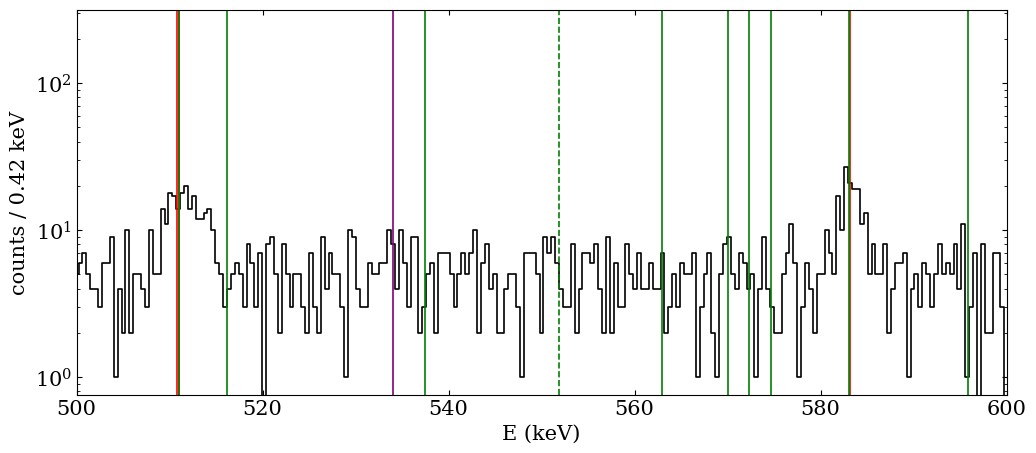

In [ ]:
plt.figure(figsize=(12,5))
plt.step(E_tot, Ntot, where="mid", color="black")
plt.axvline(SIGNAL["mu"], color = 'green', ls = '--')

for p in peaks:
    plt.axvline(p,  color = 'red')
for p in peaks_lines:
    plt.axvline(p,  color = 'green')
plt.axvline(534,  color = 'purple')
plt.yscale('log')
plt.xlim(SIGNAL["roi"][0], SIGNAL["roi"][1])
plt.ylabel("counts / 0.42 keV")
plt.xlabel("E (keV)")

In [ ]:
FILES['50d']['path']

'csv-files/zro2_white&green_ 50_days.csv'

In [ ]:
BACKGROUND_PEAKS = {
    #"²²⁸Ac ": {"E": 572.3, "N": 3.55},
    "²²⁸Ac": {"E": 509, "N": 3.55},
    "²⁰⁸Tl2":{"E":510.77, "N":0},
    "ann": {"E":511, "N":0},
    "²⁰⁸Tl" :  {"E": 583.191, "N":0},
    #"p1" :  {"E": 534, "N":0}
}

In [ ]:
roi_mask = (
    (E_tot > SIGNAL["roi"][0]) &
    (E_tot < SIGNAL["roi"][1])
)

E_roi = E_tot[roi_mask]
counts_roi = Ntot[roi_mask]

In [ ]:
bin_edges = BINS
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# ============================================================
# ROI
# ============================================================
roi_mask = (
    (bin_centers >= SIGNAL["roi"][0]) &
    (bin_centers <= SIGNAL["roi"][1])
)

# Conteggi nella ROI
counts_roi = Ntot[roi_mask]

# Centri dei bin nella ROI
E_roi = bin_centers[roi_mask]

# Edge dei bin nella ROI
idx = np.where(roi_mask)[0]
bin_edges_roi = bin_edges[idx[0]:idx[-1] + 2]

# Larghezza dei bin (costante)
bin_width = bin_edges_roi[1] - bin_edges_roi[0]

In [ ]:
edges_low = bin_edges_roi[:-1]
edges_high = bin_edges_roi[1:]

# ============================================================
# BACKGROUND PEAKS
# ============================================================
#
# I contributi:
#
#   ²²⁸Ac   -> 509 keV
#   ²⁰⁸Tl2  -> 510.77 keV
#   ann     -> 511 keV
#
# vengono trattati come UN SOLO picco composito.
#
# Gli altri picchi restano separati.
# ============================================================

BACKGROUND_PEAKS = {

    # Picco composito 509 - 511 keV
    "²²⁸Ac+²⁰⁸Tl+ann": {
        "E": 511.0
    },

    "²⁰⁸Tl": {
        "E": 583.191
    },
}


# ============================================================
# CDF GAUSSIANA - PyTensor safe
# ============================================================

def gaussian_cdf(x, mu, sigma):

    return 0.5 * (
        1.0
        + pt.erf(
            (x - mu) /
            (sigma * pt.sqrt(2.0))
        )
    )


# ============================================================
# INTEGRAL OF GAUSSIAN INSIDE EACH BIN
# ============================================================

def bin_integral(mu, sigma, low, high):

    return (
        gaussian_cdf(
            high,
            mu,
            sigma
        )
        -
        gaussian_cdf(
            low,
            mu,
            sigma
        )
    )


In [ ]:
# ============================================================
# MODEL
# ============================================================

with pm.Model() as model:

    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================

    A_bg = []
    mu_bg = []
    sigma_bg = []

    for name, fit in BACKGROUND_PEAKS.items():

        # ----------------------------------------------------
        # AREA TOTALE DEL PICCO
        # ----------------------------------------------------

        #A = pm.HalfNormal(
        A = pm.HalfFlat(
            f"A_{name}",
            #sigma=5 * np.max(counts_roi),
        )

        # ----------------------------------------------------
        # POSIZIONE DEL PICCO
        # ----------------------------------------------------

        if name == "²²⁸Ac+²⁰⁸Tl+ann":

            # Centro efficace del gruppo composito 509–511 keV
            mu = pm.Normal(
                f"mu_{name}",
                mu=511.0,
                sigma=1.0,
            )

        else:

            mu = pm.Normal(
                f"mu_{name}",
                mu=fit["E"],
                sigma=0.1,
            )

        # ----------------------------------------------------
        # SIGMA DEL PICCO
        # ----------------------------------------------------

        if name == "²²⁸Ac+²⁰⁸Tl+ann":

            # Larghezza efficace del picco composito
            sigma_i = pm.HalfNormal(
                f"sigma_{name}",
                sigma=2.0,
            )

        else:

            # Risoluzione strumentale, salvata nel trace
            sigma_i = pm.Deterministic(
                f"sigma_{name}",
                sigma_fun(mu),
            )

        A_bg.append(A)
        mu_bg.append(mu)
        sigma_bg.append(sigma_i)

    # ========================================================
    # STACK PYTENSOR
    # ========================================================

    A_bg = pt.stack(A_bg)
    mu_bg = pt.stack(mu_bg)
    sigma_bg = pt.stack(sigma_bg)

    # ========================================================
    # SIGNAL
    # ========================================================

    #A_signal = pm.HalfNormal(
    A_signal = pm.HalfFlat(
        "A_signal",
        #sigma=np.max(counts_roi),
    )

    mu_signal = pm.Normal(
        "mu_signal",
        mu=SIGNAL["mu"],
        sigma=0.25,
    )

    # Risoluzione strumentale del segnale, salvata nel trace
    sigma_signal = pm.Deterministic(
        "sigma_signal",
        sigma_fun(mu_signal),
    )

    # ========================================================
    # FLAT BACKGROUND
    # ========================================================

    bin_width = edges_high - edges_low

    # Q: densità di conteggi del fondo, in conteggi/keV.
    # La scala della prior viene convertita da conteggi/bin.
    Q = pm.HalfNormal(
        "Q",
        sigma=np.mean(counts_roi) / np.mean(bin_width),
    )

    Q_bins = Q * bin_width

    # ========================================================
    # SIGNAL — EXACT BIN INTEGRALS
    # ========================================================

    sig = bin_integral(
        mu_signal,
        sigma_signal,
        edges_low,
        edges_high,
    )

    # ========================================================
    # BACKGROUND — EXACT BIN INTEGRALS
    # ========================================================

    bg = pt.stack([
        bin_integral(
            mu_bg[i],
            sigma_bg[i],
            edges_low,
            edges_high,
        )
        for i in range(len(BACKGROUND_PEAKS))
    ])

    # ========================================================
    # EXPECTATION PER BIN
    # ========================================================

    lambda_E = (
        Q_bins
        + A_signal * sig
        + pt.sum(A_bg[:, None] * bg, axis=0)
    )

    # ========================================================
    # SAFETY
    # ========================================================

    lambda_E = pt.clip(
        lambda_E,
        1e-9,
        np.inf,
    )

    # ========================================================
    # LIKELIHOOD
    # ========================================================

    pm.Poisson(
        "obs",
        mu=lambda_E,
        observed=counts_roi,
    )

    # ========================================================
    # SAMPLING
    # ========================================================

    trace = pm.sample(
        draws=4000,
        tune=4000,
        chains=4,
        cores=min(4, multiprocessing.cpu_count()),
        target_accept=0.99,
        init="jitter+adapt_diag",
        return_inferencedata=True,
        progressbar=False,
        random_seed=123,
    )


# ============================================================
# STAMPA DEI VALORI NUMERICI DI SIGMA
# ============================================================

print("\n Background peak sigmas:")

for name in BACKGROUND_PEAKS:

    sigma_values = trace.posterior[f"sigma_{name}"].values

    sigma_mean = np.mean(sigma_values)
    sigma_std = np.std(sigma_values)

    print(
        f"  {name}: "
        f"sigma = {sigma_mean:.4f} ± {sigma_std:.4f} keV"
    )

print("\n Signal sigma:")

sigma_values = trace.posterior["sigma_signal"].values

sigma_mean = np.mean(sigma_values)
sigma_std = np.std(sigma_values)

print(
    f"  Signal: "
    f"sigma = {sigma_mean:.4f} ± {sigma_std:.4f} keV"
)

Initializing NUTS using jitter+adapt_diag...
/home/ritaferi/pymc-env/lib/python3.12/site-packages/pytensor/link/c/cmodule.py:2986: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A_²²⁸Ac+²⁰⁸Tl+ann, mu_²²⁸Ac+²⁰⁸Tl+ann, sigma_²²⁸Ac+²⁰⁸Tl+ann, A_²⁰⁸Tl, mu_²⁰⁸Tl, A_signal, mu_signal, Q]
Sampling 4 chains for 4_000 tune and 4_000 draw iterations (16_000 + 16_000 draws total) took 1


 Background peak sigmas:
  ²²⁸Ac+²⁰⁸Tl+ann: sigma = 1.8041 ± 0.1953 keV
  ²⁰⁸Tl: sigma = 0.8360 ± 0.0000 keV

 Signal sigma:
  Signal: sigma = 0.8234 ± 0.0001 keV


In [ ]:
import multiprocessing

import numpy as np
import pymc as pm
import pytensor.tensor as pt


# ============================================================
# SIGMA FISSA PER SEGNALE E TALLIO
# ============================================================

# Chiave esatta del picco di tallio in BACKGROUND_PEAKS
THALLIUM_NAME = "²⁰⁸Tl"

# Se intendi il gruppo composito, usa invece:
# THALLIUM_NAME = "²²⁸Ac+²⁰⁸Tl+ann"

if THALLIUM_NAME not in BACKGROUND_PEAKS:
    raise ValueError(
        f"Il picco {THALLIUM_NAME!r} non è in BACKGROUND_PEAKS. "
        f"Chiavi disponibili: {list(BACKGROUND_PEAKS)}"
    )

# Energia nominale del segnale, in keV
E_signal = float(SIGNAL["mu"])

# Sigma calcolata una sola volta all'energia nominale del segnale
sigma_result = sigma_fun(E_signal)

if hasattr(sigma_result, "eval"):
    sigma_result = sigma_result.eval()

# Larghezza gaussiana fissa, in keV
sigma_fixed = float(np.asarray(sigma_result).item())

if not np.isfinite(sigma_fixed) or sigma_fixed <= 0:
    raise ValueError("sigma_fixed deve essere finita e positiva.")

print(
    f"Sigma fissa per segnale e {THALLIUM_NAME}: "
    f"{sigma_fixed:.4f} keV "
    f"(calcolata a E = {E_signal:.4f} keV)"
)


# ============================================================
# MODEL
# ============================================================

with pm.Model() as model:

    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================

    A_bg = []
    mu_bg = []
    sigma_bg = []

    for name, fit in BACKGROUND_PEAKS.items():

        # ----------------------------------------------------
        # AREA TOTALE DEL PICCO
        # ----------------------------------------------------

        A = pm.HalfNormal(
            f"A_{name}",
            sigma=5 * np.max(counts_roi),
        )

        # ----------------------------------------------------
        # POSIZIONE DEL PICCO
        # ----------------------------------------------------

        if name == "²²⁸Ac+²⁰⁸Tl+ann":

            mu = pm.Normal(
                f"mu_{name}",
                mu=511.0,
                sigma=1.0,
            )

        else:

            mu = pm.Normal(
                f"mu_{name}",
                mu=fit["E"],
                sigma=0.1,
            )

        # ----------------------------------------------------
        # SIGMA DEL PICCO
        # ----------------------------------------------------

        if name == THALLIUM_NAME:

            # Stessa sigma fissa del segnale
            sigma_i = pm.Deterministic(
                f"sigma_{name}",
                pt.as_tensor_variable(sigma_fixed),
            )

        elif name == "²²⁸Ac+²⁰⁸Tl+ann":

            # Sigma libera per il gruppo composito,
            # se non è stato scelto come THALLIUM_NAME
            sigma_i = pm.HalfNormal(
                f"sigma_{name}",
                sigma=2.0,
            )

        else:

            # Risoluzione degli altri picchi
            sigma_i = pm.Deterministic(
                f"sigma_{name}",
                sigma_fun(mu),
            )

        A_bg.append(A)
        mu_bg.append(mu)
        sigma_bg.append(sigma_i)

    # ========================================================
    # STACK PYTENSOR
    # ========================================================

    A_bg = pt.stack(A_bg)
    mu_bg = pt.stack(mu_bg)
    sigma_bg = pt.stack(sigma_bg)

    # ========================================================
    # SIGNAL
    # ========================================================

    A_signal = pm.HalfNormal(
        "A_signal",
        sigma=np.max(counts_roi),
    )

    mu_signal = pm.Normal(
        "mu_signal",
        mu=SIGNAL["mu"],
        sigma=0.25,
    )

    # Sigma fissa: non dipende da mu_signal durante il fit
    sigma_signal = pm.Deterministic(
        "sigma_signal",
        pt.as_tensor_variable(sigma_fixed),
    )

    # ========================================================
    # FLAT BACKGROUND
    # ========================================================

    bin_width = edges_high - edges_low

    # Q: densità del fondo in conteggi/keV
    Q = pm.HalfNormal(
        "Q",
        sigma=np.mean(counts_roi) / np.mean(bin_width),
    )

    Q_bins = Q * bin_width

    # ========================================================
    # SIGNAL — EXACT BIN INTEGRALS
    # ========================================================

    sig = bin_integral(
        mu_signal,
        sigma_signal,
        edges_low,
        edges_high,
    )

    # ========================================================
    # BACKGROUND — EXACT BIN INTEGRALS
    # ========================================================

    bg = pt.stack([
        bin_integral(
            mu_bg[i],
            sigma_bg[i],
            edges_low,
            edges_high,
        )
        for i in range(len(BACKGROUND_PEAKS))
    ])

    # ========================================================
    # EXPECTATION PER BIN
    # ========================================================

    lambda_E = (
        Q_bins
        + A_signal * sig
        + pt.sum(
            A_bg[:, None] * bg,
            axis=0,
        )
    )

    # ========================================================
    # SAFETY
    # ========================================================

    lambda_E = pt.clip(
        lambda_E,
        1e-9,
        np.inf,
    )

    # ========================================================
    # LIKELIHOOD
    # ========================================================

    pm.Poisson(
        "obs",
        mu=lambda_E,
        observed=counts_roi,
    )

    # ========================================================
    # SAMPLING
    # ========================================================

    trace = pm.sample(
        draws=4000,
        tune=4000,
        chains=4,
        cores=min(4, multiprocessing.cpu_count()),
        target_accept=0.99,
        init="jitter+adapt_diag",
        return_inferencedata=True,
        progressbar=False,
        random_seed=123,
    )


# ============================================================
# STAMPA DELLE SIGMA
# ============================================================

print("\n Background peak sigmas:")

for name in BACKGROUND_PEAKS:

    if name == THALLIUM_NAME:

        print(
            f"  {name}: "
            f"sigma = {sigma_fixed:.4f} keV (fixed)"
        )

    else:

        sigma_values = trace.posterior[f"sigma_{name}"].values

        sigma_mean = np.mean(sigma_values)
        sigma_std = np.std(sigma_values)

        print(
            f"  {name}: "
            f"sigma = {sigma_mean:.4f} ± {sigma_std:.4f} keV"
        )

print("\n Signal sigma:")

print(
    f"  Signal: "
    f"sigma = {sigma_fixed:.4f} keV (fixed)"
)

Sigma fissa per segnale e ²⁰⁸Tl: 0.8234 keV (calcolata a E = 551.9000 keV)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A_²²⁸Ac+²⁰⁸Tl+ann, mu_²²⁸Ac+²⁰⁸Tl+ann, sigma_²²⁸Ac+²⁰⁸Tl+ann, A_²⁰⁸Tl, mu_²⁰⁸Tl, A_signal, mu_signal, Q]
Sampling 4 chains for 4_000 tune and 4_000 draw iterations (16_000 + 16_000 draws total) took 15 seconds.



 Background peak sigmas:
  ²²⁸Ac+²⁰⁸Tl+ann: sigma = 1.7996 ± 0.1961 keV
  ²⁰⁸Tl: sigma = 0.8234 keV (fixed)

 Signal sigma:
  Signal: sigma = 0.8234 keV (fixed)


In [ ]:
summary = az.summary(trace, round_to=4)
summary


/home/ritaferi/pymc-env/lib/python3.12/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_²²⁸Ac+²⁰⁸Tl+ann,511.6595,0.2300,511.2295,512.0929,0.0019,0.0019,14845.5718,11875.5783,1.0001
mu_²⁰⁸Tl,583.2039,0.0798,583.0519,583.3511,0.0006,0.0006,15915.1454,12025.6684,1.0000
mu_signal,551.7874,0.2535,551.3116,552.2600,0.0021,0.0019,14612.8431,12158.1416,1.0002
A_²²⁸Ac+²⁰⁸Tl+ann,139.0494,15.9995,108.4672,168.4307,0.1385,0.1213,13228.7423,11430.8312,1.0001
sigma_²²⁸Ac+²⁰⁸Tl+ann,1.7996,0.1961,1.4407,2.1748,0.0018,0.0016,11900.3991,10850.8938,1.0002
A_²⁰⁸Tl,96.7176,11.7286,74.8297,118.6171,0.0988,0.0924,13914.9881,9512.8989,1.0004
A_signal,7.5828,5.2521,0.0013,16.7445,0.0446,0.0401,9394.6296,5548.1870,0.9999
Q,11.8937,0.3676,11.2305,12.5947,0.0033,0.0028,12546.1797,11760.4434,1.0000
sigma_²⁰⁸Tl,0.8234,0.0000,0.8234,0.8234,0.0000,0.0000,16000.0000,16000.0000,NaN
sigma_signal,0.8234,0.0000,0.8234,0.8234,0.0000,0.0000,16000.0000,16000.0000,NaN


In [ ]:
def fun_sigma_fun(E):

    A = 3.68436e1
    B = 1.72714e4

    return (
        E * np.sqrt(A/E + B/E**2)
        / 2.355
        / 100
    )


fun_sigma_fun(552)

np.float64(0.8234843870237889)

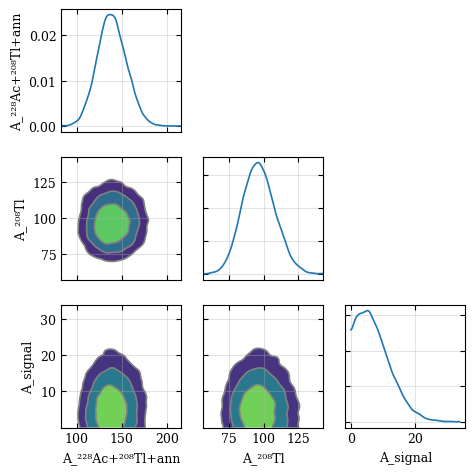

In [ ]:

# ============================================================
# CORRELATION PLOTS
# ============================================================
A_vars = [v for v in trace.posterior.data_vars if v.startswith("A_")]

axes = az.plot_pair(
    trace,
    var_names=A_vars,
    kind="kde",
    marginals=True,
    figsize=(5,5),
    textsize=9,
)

for ax in axes.flatten():
    ax.grid(alpha=0.35)

plt.tight_layout()
plt.show()


In [ ]:


# ============================================================
# POSTERIOR OF SIGNAL
# ============================================================
signal_samples = trace.posterior["A_signal"].values.flatten()

N_signal_90 = np.percentile(signal_samples, 90)
N_signal_95 = np.percentile(signal_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on signal counts : {N_signal_90:.3f}")
print(f"95% upper limit on signal counts : {N_signal_95:.3f}")
print("=" * 60)


90% upper limit on signal counts : 14.814
95% upper limit on signal counts : 17.485


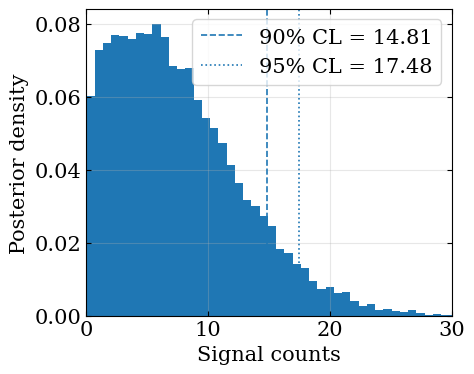

In [ ]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================
plt.figure(figsize=(5, 4))

plt.hist(signal_samples, bins=50, density=True)

plt.axvline(
    
    N_signal_90,
    linestyle="--",
    label=f"90% CL = {N_signal_90:.2f}",
)

plt.axvline(
    N_signal_95,
    linestyle=":",
    label=f"95% CL = {N_signal_95:.2f}",
)

plt.xlabel("Signal counts")
plt.ylabel("Posterior density")
plt.grid(alpha=0.3)
plt.legend()
plt.xlim(0, 30)
plt.tight_layout()
plt.show()



In [ ]:
# ============================================================
# POSTERIOR EXTRACTION
# ============================================================

background_names = list(BACKGROUND_PEAKS.keys())

idata = trace
posterior = idata.posterior

# ============================================================
# FLAT BACKGROUND
# ============================================================

Q_s = posterior["Q"].values.reshape(-1)


# ============================================================
# SIGNAL
# ============================================================

A_signal_s = posterior["A_signal"].values.reshape(-1)

mu_signal_s = posterior["mu_signal"].values.reshape(-1)

# sigma del signal calcolata sui campioni posteriori
sigma_signal_s = (
    mu_signal_s
    * np.sqrt(
        3.68436e1 / mu_signal_s
        + 1.72714e4 / mu_signal_s**2
    )
    / 2.355
    / 100
)


# ============================================================
# BACKGROUND AREAS
# ============================================================

A_bg_s = {
    name: posterior[f"A_{name}"].values.reshape(-1)
    for name in background_names
}


# ============================================================
# BACKGROUND POSITIONS
# ============================================================

mu_bg_s = {
    name: posterior[f"mu_{name}"].values.reshape(-1)
    for name in background_names
}


# ============================================================
# BACKGROUND SIGMAS
# ============================================================

sigma_bg_s = {}

for name in background_names:

    # --------------------------------------------------------
    # PICCO COMPOSITO 509-510.77-511 keV
    # --------------------------------------------------------

    if name == "²²⁸Ac+²⁰⁸Tl+ann":

        # sigma è un parametro libero del modello
        sigma_bg_s[name] = (
            posterior[f"sigma_{name}"]
            .values
            .reshape(-1)
        )

    # --------------------------------------------------------
    # ALTRI PICCHI DI BACKGROUND
    # --------------------------------------------------------

    else:

        # sigma = sigma_fun(mu)
        # Calcolata in NumPy sui campioni posteriori

        mu = mu_bg_s[name]

        sigma_bg_s[name] = (
            mu
            * np.sqrt(
                3.68436e1 / mu
                + 1.72714e4 / mu**2
            )
            / 2.355
            / 100
        )

In [ ]:
import numpy as np
import scipy.special


# ============================================================
# ESTRAZIONE POSTERIOR DEI PARAMETRI
# ============================================================

posterior = trace.posterior

n_posterior_samples = (
    posterior.sizes["chain"]
    *
    posterior.sizes["draw"]
)

print(
    f"Number of posterior samples: "
    f"{n_posterior_samples}"
)


# ============================================================
# SIGNAL PARAMETERS
# ============================================================

A_signal_s = (
    posterior["A_signal"]
    .values
    .flatten()
)

mu_signal_s = (
    posterior["mu_signal"]
    .values
    .flatten()
)


# ============================================================
# FLAT BACKGROUND
# ============================================================

Q_s = (
    posterior["Q"]
    .values
    .flatten()
)


# ============================================================
# BACKGROUND PEAK PARAMETERS
# ============================================================

background_names = list(BACKGROUND_PEAKS.keys())

A_bg_s = []
mu_bg_s = []

for name in background_names:

    A_bg_s.append(
        posterior[f"A_{name}"]
        .values
        .flatten()
    )

    mu_bg_s.append(
        posterior[f"mu_{name}"]
        .values
        .flatten()
    )


# Trasformo in NumPy array
#
# shape:
#   A_bg_s  -> (N_background, N_samples)
#   mu_bg_s -> (N_background, N_samples)

A_bg_s = np.array(A_bg_s)
mu_bg_s = np.array(mu_bg_s)


print("A_bg shape:", A_bg_s.shape)
print("mu_bg shape:", mu_bg_s.shape)


# ============================================================
# BACKGROUND SIGMAS POSTERIOR
# ============================================================

sigma_bg_s = []

for name in background_names:

    # --------------------------------------------------------
    # PICCO COMPOSITO 509-510.77-511 keV
    # --------------------------------------------------------

    if name == "²²⁸Ac+²⁰⁸Tl+ann":

        # sigma è un parametro libero del modello

        sigma_samples = (
            posterior[f"sigma_{name}"]
            .values
            .flatten()
        )

    # --------------------------------------------------------
    # ALTRI PICCHI
    # --------------------------------------------------------

    else:

        # sigma = sigma_fun(mu)
        #
        # Formula equivalente a quella usata nel modello

        mu = mu_bg_s[
            background_names.index(name)
        ]

        sigma_samples = (
            mu
            * np.sqrt(
                3.68436e1 / mu
                + 1.72714e4 / mu**2
            )
            / 2.355
            / 100
        )

    sigma_bg_s.append(sigma_samples)


# Array finale:
#
# shape:
#   (N_background, N_samples)

sigma_bg_s = np.array(sigma_bg_s)

print(
    "sigma_bg shape:",
    sigma_bg_s.shape
)


# ============================================================
# STORAGE DELLE CURVE POSTERIOR
# ============================================================

# Numero di curve da usare per la visualizzazione/statistiche
n_curves = 5000
lambda_total_samples = []
lambda_bkg_samples = []


# ============================================================
# LOOP SUI CAMPIONI POSTERIOR
# ============================================================

for i in range(n_curves):


    # ========================================================
    # SIGNAL
    # ========================================================

    mu_sig = mu_signal_s[i]

    # Risoluzione del segnale:
    #
    # sigma = sigma_fun(mu_signal)

    sigma_sig = (
        mu_sig
        * np.sqrt(
            3.68436e1 / mu_sig
            + 1.72714e4 / mu_sig**2
        )
        / 2.355
        / 100
    )


    # --------------------------------------------------------
    # SIGNAL BIN INTEGRAL
    # --------------------------------------------------------

    sig_integral = (
        0.5
        * (
            1.0
            + scipy.special.erf(
                (edges_high - mu_sig)
                /
                (sigma_sig * np.sqrt(2.0))
            )
        )
        -
        0.5
        * (
            1.0
            + scipy.special.erf(
                (edges_low - mu_sig)
                /
                (sigma_sig * np.sqrt(2.0))
            )
        )
    )


    # --------------------------------------------------------
    # SIGNAL CONTRIBUTION
    # --------------------------------------------------------

    signal_i = (
        A_signal_s[i]
        *
        sig_integral
    )


    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================

    bg_i = np.zeros_like(
        edges_low,
        dtype=float
    )


    for j, name in enumerate(background_names):


        # ----------------------------------------------------
        # BACKGROUND MU
        # ----------------------------------------------------

        mu_bg_i = mu_bg_s[j, i]


        # ----------------------------------------------------
        # BACKGROUND SIGMA
        # ----------------------------------------------------

        sigma_bg_i = sigma_bg_s[j, i]


        # ----------------------------------------------------
        # BACKGROUND BIN INTEGRAL
        # ----------------------------------------------------

        bg_integral = (
            0.5
            * (
                1.0
                + scipy.special.erf(
                    (edges_high - mu_bg_i)
                    /
                    (sigma_bg_i * np.sqrt(2.0))
                )
            )
            -
            0.5
            * (
                1.0
                + scipy.special.erf(
                    (edges_low - mu_bg_i)
                    /
                    (sigma_bg_i * np.sqrt(2.0))
                )
            )
        )


        # ----------------------------------------------------
        # BACKGROUND PEAK CONTRIBUTION
        # ----------------------------------------------------

        bg_i += (
            A_bg_s[j, i]
            *
            bg_integral
        )


    # ========================================================
    # FLAT BACKGROUND
    # ========================================================

    flat_i = (
        Q_s[i]
        *
        bin_width
    )


    # ========================================================
    # BACKGROUND ONLY
    # ========================================================

    bkg_model_i = (
        flat_i
        +
        bg_i
    )


    # ========================================================
    # TOTAL MODEL
    # ========================================================

    total_model_i = (
        bkg_model_i
        +
        signal_i
    )


    # ========================================================
    # STORAGE
    # ========================================================

    lambda_bkg_samples.append(
        bkg_model_i
    )

    lambda_total_samples.append(
        total_model_i
    )


# ============================================================
# ARRAY FINALI
# ============================================================

lambda_bkg_samples = np.array(
    lambda_bkg_samples
)

lambda_total_samples = np.array(
    lambda_total_samples
)


print(
    "Total posterior curves:",
    lambda_total_samples.shape
)

print(
    "Background posterior curves:",
    lambda_bkg_samples.shape
)


# ============================================================
# STATISTICHE POSTERIOR
# ============================================================

# ------------------------------------------------------------
# TOTAL MODEL
# ------------------------------------------------------------

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

lambda_total_low = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)

lambda_total_high = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)


# ------------------------------------------------------------
# BACKGROUND ONLY
# ------------------------------------------------------------

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)

lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)


print("Done.")

Number of posterior samples: 16000
A_bg shape: (2, 16000)
mu_bg shape: (2, 16000)
sigma_bg shape: (2, 16000)
Total posterior curves: (5000, 239)
Background posterior curves: (5000, 239)
Done.


In [ ]:
# ============================================================
# POSTERIOR SUMMARY
# ============================================================

# totale
fit_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

fit_total_low_68 = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)

fit_total_high_68 = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)


fit_total_low_95 = np.percentile(
    lambda_total_samples,
    2.5,
    axis=0
)

fit_total_high_95 = np.percentile(
    lambda_total_samples,
    97.5,
    axis=0
)



# background
fit_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

fit_bkg_low_68 = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)

fit_bkg_high_68 = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)


fit_bkg_low_95 = np.percentile(
    lambda_bkg_samples,
    2.5,
    axis=0
)

fit_bkg_high_95 = np.percentile(
    lambda_bkg_samples,
    97.5,
    axis=0
)

In [ ]:
# ============================================================
# POSTERIOR SUMMARY
# ============================================================

# totale
fit_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

fit_total_low_68 = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)

fit_total_high_68 = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)


fit_total_low_95 = np.percentile(
    lambda_total_samples,
    2.5,
    axis=0
)

fit_total_high_95 = np.percentile(
    lambda_total_samples,
    97.5,
    axis=0
)



# background
fit_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

fit_bkg_low_68 = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)

fit_bkg_high_68 = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)


fit_bkg_low_95 = np.percentile(
    lambda_bkg_samples,
    2.5,
    axis=0
)

fit_bkg_high_95 = np.percentile(
    lambda_bkg_samples,
    97.5,
    axis=0
)

In [ ]:
# ============================================================
# BAYESIAN FIT BAND
# ============================================================

# lambda_total_samples:
# (N_posterior_samples, N_bins)

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

lambda_total_low = np.percentile(
    lambda_total_samples,
    5,
    axis=0
)

lambda_total_high = np.percentile(
    lambda_total_samples,
    95,
    axis=0
)


# background only

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    5,
    axis=0
)

lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    95,
    axis=0
)



# ============================================================
# RESIDUALS
# ============================================================

residuals = (
    counts_roi - lambda_total_mean
) / np.sqrt(lambda_total_mean + 1e-9)



# ============================================================
# BIN CENTERS
# ============================================================

E_roi = 0.5*(edges_low + edges_high)



# ============================================================
# FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    sharex=True,
    gridspec_kw={"height_ratios": [3,1]},
    figsize=(8,6),
    dpi = 300
)



# ============================================================
# DATA
# ============================================================

ax1.step(
    E_roi,
    counts_roi,
    where="mid",
    color="grey",
    alpha=0.7,
    label="Data"
)



# ============================================================
# TOTAL BAYESIAN MODEL
# ============================================================

ax1.plot(
    E_roi,
    lambda_total_mean,
    #where="mid",
    color="green",
    lw=2,
    label="Posterior mean"
)


ax1.fill_between(
    E_roi,
    lambda_total_low,
    lambda_total_high,
    #step="mid",
    color="green",
    alpha=0.2,
    #label="68% credible interval"
)



# ============================================================
# BACKGROUND ONLY
# ============================================================

ax1.plot(
    E_roi,
    lambda_bkg_mean,
    #where="mid",
    color="red",
    lw=2,
    label="Background"
)


ax1.fill_between(
    E_roi,
    lambda_bkg_low,
    lambda_bkg_high,
    #step="mid",
    color="red",
    alpha=0.2
)


for name, peak in BACKGROUND_PEAKS.items():

    mu_samples = (
        trace.posterior[f"mu_{name}"]
        .values
        .flatten()
    )

    mu_fit = np.mean(mu_samples)

    ax1.axvline(
        mu_fit,
        color="black",
        linestyle="--",
        alpha=0.6,
        lw=1
    )

    x_text = mu_fit + 1.25 if name == "p" else mu_fit - 2.5

    ax1.text(
        x_text,
        30,
        f"{name}",
        rotation=90,
        verticalalignment="bottom",
        horizontalalignment="center",
        fontsize=14
    )



# ============================================================
# SIGNAL LINE
# ============================================================

ax1.axvline(
    SIGNAL["mu"],
    color="black",
    linestyle="--",
    alpha=0.6
)


ax1.text(
    SIGNAL["mu"]-2,
    40,
    "551.9 keV",
    rotation=90,
    verticalalignment="bottom",
    horizontalalignment="center",
    fontsize=14
)



# ============================================================
# AXES
# ============================================================

ax1.set_yscale("log")

ax1.set_xlim(
    E_roi.min(),
    E_roi.max()
)


ax1.set_ylim(
    3.5,
    250
    
)


ax1.set_ylabel(
    f"Counts / {edges_high[0]-edges_low[0]:.2f} keV"
)


ax1.grid(alpha=0.15)


ax1.legend(
    loc="lower center",
    bbox_to_anchor=(0.5,0.98),
    ncol=3
)



# ============================================================
# RESIDUALS
# ============================================================

ax2.scatter(
    E_roi,
    residuals,
    s=10,
    color="black",
    zorder = 5
)


ax2.axhspan(
    -3,
    3,
    color="red",
    alpha=0.2
)


ax2.axhspan(
    -2,
    2,
    color="orange",
    alpha=0.2
)


ax2.axhspan(
    -1,
    1,
    color="green",
    alpha=0.15
)


ax2.axhline(
    0,
    color="gray",
    lw=1,
    zorder=2
)



ax2.set_xlabel(
    "Energy [keV]"
)


ax2.set_ylabel(
    "Pulls"
)


ax2.set_ylim(
    -5,
    5
)


ax2.grid(alpha=0.2)



plt.subplots_adjust(hspace=0)

plt.show()

In [ ]:
fun_sigma_fun(551.9)

np.float64(0.8234440498461848)

# half life

In [ ]:
# Dati campione
m_sample = 551.3        # massa ZrO2 in grammi
Mr_sample = 123.22      # massa molare ZrO2 [g/mol]
N_A = 6.022e23          # numero di Avogadro
eff_96Zr = 0.032244    # efficienza di rivelazione
i_a_96Zr = 0.0280     # abbondanza isotopica
t_live =  t_tot/(60*60*24*365)             # 90 giorni in anni


# Numero di nuclei 96Zr nel campione
N_nuclei = (m_sample * i_a_96Zr / Mr_sample) * N_A


In [ ]:
N_signal_90

np.float64(14.81403713003282)

In [ ]:

percentile = 90

T_half_limit = (np.log(2) * N_nuclei * eff_96Zr * t_live) / N_signal_90
print(f"T1/2 > {T_half_limit:.2e} yrs at {percentile}%")

T1/2 > 4.27e+19 yrs at 90%


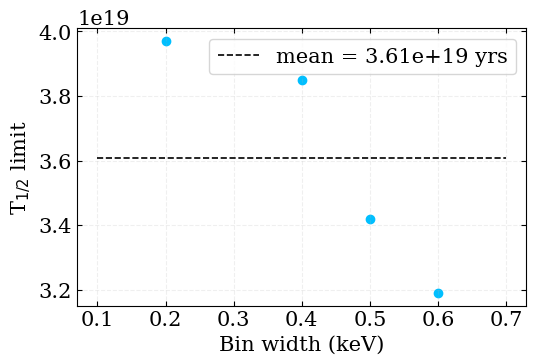

In [ ]:
limit = [3.97e19, 3.85e19, 3.42e19, 3.19e+19 ]# 0.8]

bin_width = [0.2, 0.4, 0.5, 0.6]

plt.scatter(bin_width, limit, color = 'deepskyblue')
plt.hlines(np.mean(limit), min(bin_width)-0.1, max(bin_width)+0.1, color = 'black', ls = '--', label = f"mean = {np.mean(limit):.2e} yrs")
plt.ylabel(fr"T$_{{1/2}}$ limit")
plt.xlabel('Bin width (keV)')
plt.legend()
plt.grid(alpha = 0.2, ls = '--')

# activities

In [ ]:
counts_vars = [
    v for v in trace.posterior.data_vars
    if v.startswith("A_") and v != "A_signal"
]
counts_vars

['A_²²⁸Ac+²⁰⁸Tl+ann', 'A_²⁰⁸Tl']

In [ ]:
counts_vars = [
    v for v in trace.posterior.data_vars
    if v.startswith("A_") and v != "A_signal"
]

counts_vars = counts_vars[:-1]

eff = np.array([
     0.0288,   # 228Ac 755.3 keV
     0.0288,   # 95Zr 756.73 keV
     0.0288,  # 95Nb 765.80 keV
     0.027,   # 214Bi 768.4 keV
     0.027,   # 214Pb 785.5/785.96 keV
     0.0288,   # 228Ac 794.947 keV
])

I = np.array([
    0.045,
    0.2261,
    1,
    0.8448,
    1
    
])

t_tot = 11829409       # s
m_sample_kg = m_sample * 0.001

for v, epsilon, br in zip(counts_vars, eff, I):

    samples = trace.posterior[v].values.flatten()

    activity = samples / (
        t_tot
        * m_sample_kg
        * epsilon
        * br
    )

    print(
        f"{v}: "
        f"{activity.mean()*1e3:.3f} ± "
        f"{activity.std()*1e3:.3f} mBq/kg"
    )

A_²²⁸Ac+²⁰⁸Tl+ann: 16.452 ± 1.893 mBq/kg


<!-- questa cosa che ho fatto sotto non ha molto senso. nel picco estratto ho il contributo di 3 picchi di cui uno posso ottenere l'attività vera, ma poi ho il picco di annichilazione -->

In [ ]:
import math
from scipy.stats import norm

def zeta_test(A1, u1, A2, u2):
    # Zeta score
    zeta = (A1 - A2) / math.sqrt(u1**2 + u2**2)

    # Two-sided p-value
    p_value = 2 * norm.sf(abs(zeta))

    return zeta, p_value


# Esempio
# Valore 1
A1 = 0.657
u1 = 0.080


# Valore 2
A2 = 0.39
u2 = 0.05

zeta, p = zeta_test(A1, u1, A2, u2)

print(f"Zeta = {zeta:.3f}")
print(f"p-value = {p:.4f}")

if p >= 0.05:
    print("I due valori sono compatibili (p >= 0.05).")
else:
    print("I due valori sono significativamente differenti (p < 0.05).")

Zeta = 2.830
p-value = 0.0047
I due valori sono significativamente differenti (p < 0.05).
